# Exploratory Analysis

This notebook explores the **synthetic** applicant data and reads the pipeline outputs. It is for exploration and presentation only: every headline number is produced by `python scripts/run_pipeline.py`, not by this notebook.

Run the pipeline first so `data/processed/` and `outputs/tables/` exist.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(ROOT / "data/processed/applications_scored.csv")
scen = pd.read_csv(ROOT / "outputs/tables/scenario_results.csv")
print(f"{len(df):,} applicants, {df['observed_default'].mean():.1%} would default if all were approved")

100,000 applicants, 13.3% would default if all were approved


## 1. What the applicant pool looks like

In [2]:
cols = ["annual_income", "credit_score", "debt_to_income_ratio", "revolving_utilization",
        "recent_delinquencies", "requested_loan_amount", "loan_to_income_ratio"]
df[cols].describe(percentiles=[0.1, 0.5, 0.9]).T.round(3)

,count,mean,std,min,10%,50%,90%,max
annual_income,100000.0,67738.269,40626.034,12000.000,28500.000,58000.000,118500.000,500000.000
credit_score,100000.0,679.743,69.195,384.000,591.000,680.000,769.000,850.000
debt_to_income_ratio,100000.0,0.221,0.092,0.017,0.107,0.212,0.349,0.557
revolving_utilization,100000.0,0.368,0.224,0.003,0.097,0.334,0.700,0.986
recent_delinquencies,100000.0,0.248,0.569,0.000,0.000,0.000,1.000,9.000
requested_loan_amount,100000.0,13836.620,7781.356,1500.000,6000.000,12000.000,24000.000,50000.000
loan_to_income_ratio,100000.0,0.250,0.168,0.011,0.094,0.207,0.455,2.750


## 2. Do the risk relationships look sensible?

Default rate should rise as credit score falls and as DTI and utilization rise, with noise rather than hard cut-offs.

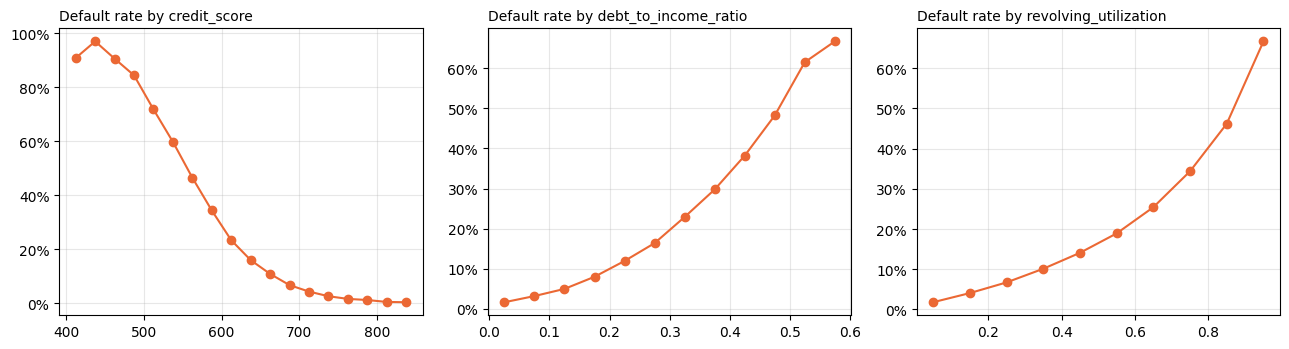

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, bins in [
    (axes[0], "credit_score", range(400, 851, 25)),
    (axes[1], "debt_to_income_ratio", [i / 100 for i in range(0, 61, 5)]),
    (axes[2], "revolving_utilization", [i / 10 for i in range(0, 11)]),
]:
    rate = df.groupby(pd.cut(df[col], bins), observed=True)["observed_default"].mean()
    ax.plot([b.mid for b in rate.index], rate.values, marker="o", color="#eb6834")
    ax.set_title(f"Default rate by {col}", loc="left", fontsize=10)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(alpha=0.3)
plt.tight_layout()

## 3. Does the Synthetic Risk Score separate defaulters from non-defaulters?

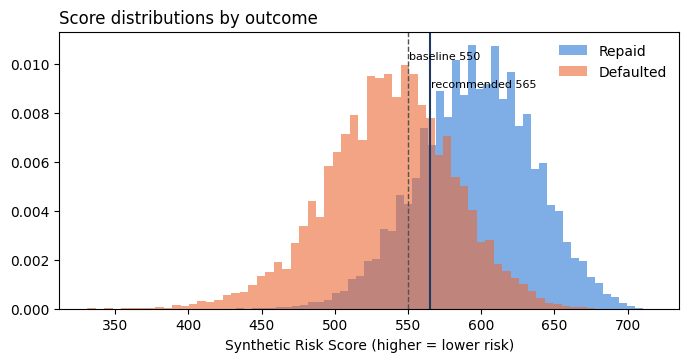

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for flag, color, label in [(0, "#2a78d6", "Repaid"), (1, "#eb6834", "Defaulted")]:
    ax.hist(df.loc[df["observed_default"] == flag, "risk_score"], bins=60, alpha=0.6,
            density=True, color=color, label=label)
ax.axvline(550, color="#52514e", ls="--", lw=1)
ax.axvline(565, color="#1f3864", ls="-", lw=1.5)
ax.text(551, ax.get_ylim()[1] * 0.9, "baseline 550", fontsize=8)
ax.text(566, ax.get_ylim()[1] * 0.8, "recommended 565", fontsize=8)
ax.set_xlabel("Synthetic Risk Score (higher = lower risk)")
ax.legend(frameon=False)
ax.set_title("Score distributions by outcome", loc="left");

## 4. Scenario results (from the pipeline)

In [5]:
view = scen[["threshold", "approval_rate", "approved_defaults", "default_rate",
             "pct_change_approvals", "pct_change_defaults", "marginal_default_rate"]]
view.style.format({"approval_rate": "{:.1%}", "default_rate": "{:.1%}", "pct_change_approvals": "{:+.1%}",
                   "pct_change_defaults": "{:+.1%}", "marginal_default_rate": "{:.1%}"}, na_rep="")

,threshold,approval_rate,approved_defaults,default_rate,pct_change_approvals,pct_change_defaults,marginal_default_rate
0,550,81.6%,5236,6.4%,+0.0%,+0.0%,
1,555,78.7%,4600,5.8%,-3.6%,-12.1%,22.0%
2,560,75.5%,4057,5.4%,-7.4%,-22.5%,17.1%
3,565,72.0%,3518,4.9%,-11.8%,-32.8%,15.2%
4,570,68.3%,3031,4.4%,-16.3%,-42.1%,13.2%
5,575,64.3%,2564,4.0%,-21.2%,-51.0%,11.6%
6,580,60.1%,2111,3.5%,-26.3%,-59.7%,10.9%
7,585,55.7%,1752,3.1%,-31.7%,-66.5%,8.2%
8,590,51.3%,1434,2.8%,-37.1%,-72.6%,7.3%
9,595,46.9%,1158,2.5%,-42.5%,-77.9%,6.2%


## 5. Querying the SQLite database directly

The same database the pipeline builds can be queried ad hoc. Example: default rate for applicants with 2+ recent delinquencies, by credit score band.

In [6]:
with sqlite3.connect(ROOT / "data/processed/credit_risk.db") as conn:
    q = '''
        SELECT credit_score_band, COUNT(*) AS applicants,
               ROUND(AVG(observed_default), 3) AS default_rate
        FROM applicant_segments
        WHERE recent_delinquencies >= 2
        GROUP BY credit_score_band, credit_score_band_order
        ORDER BY credit_score_band_order
    '''
    display(pd.read_sql_query(q, conn))

,credit_score_band,applicants,default_rate
0,<580,1708,0.713
1,580-619,927,0.428
2,620-659,708,0.275
3,660-699,351,0.114
4,700-739,127,0.102
5,740+,30,0.167


## Takeaways

* The designed relationships show up clearly and are noisy, not deterministic.
* The score separates the two outcome groups well, but the distributions overlap: any cutoff declines some good borrowers and approves some who will default. That overlap is why the cutoff is a trade-off.
* See `docs/methodology.md` for the decision rule and `outputs/executive_summary/` for the recommendation.